# Analysing interaction logs: how does AI advice change decisions?

This notebook analyses the CSV logs written by `src/viewer.py`.

**Data note:** by default it loads `logs/simulated_sessions.csv`, which is **simulated**
(see `scripts/simulate_sessions.py`). The numbers only demonstrate the analysis pipeline.
They are not study results. To analyse real sessions, set `USE_REAL_LOGS = True`.

**Protocol:** for every region the reader first gives their own decision. In `ai_on` cases
the AI advice (with high/low confidence) then appears and they give a final decision.

Questions:
1. Are final decisions more accurate, and how long do they take, with vs. without AI?
2. When the AI changes someone's mind, does that help or hurt?
3. **Automation bias and calibrated trust:** do readers follow wrong advice, and do
   they follow low-confidence advice less than high-confidence advice?

In [1]:
# In Google Colab: get the repository first (does nothing when run locally)
import sys, os
if "google.colab" in sys.modules and not os.path.exists("brain-viewer-interaction-logger"):
    !git clone -q https://github.com/iRosses-omics/brain-viewer-interaction-logger.git
    %cd brain-viewer-interaction-logger

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
USE_REAL_LOGS = False

if USE_REAL_LOGS:
    files = sorted((ROOT / "logs").glob("session_*.csv"))
    logs = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
else:
    logs = pd.read_csv(ROOT / "logs" / "simulated_sessions.csv")

print(f"{len(logs)} events, {logs.participant_id.nunique()} participants")
logs.event.value_counts()

5568 events, 12 participants


event
region_select          1536
rating_initial         1536
rating_final           1536
ai_suggestion_shown     768
case_open                96
case_complete            96
Name: count, dtype: int64

## 0. One row per decision

For every reader x case x region we join three events: `region_select`, `rating_initial`
and `rating_final` (if a region was rated twice, the last rating counts).

- `time_s`: from selecting the region to the final decision.

In [3]:
keys = ["participant_id", "case_id", "region"]

def last_of(event, cols):
    return logs[logs.event == event].groupby(keys).last()[cols]

sel = last_of("region_select", ["ms_since_case_open"]).rename(columns={"ms_since_case_open": "t_select"})
ini = last_of("rating_initial", ["rating"]).rename(columns={"rating": "initial"})
fin = last_of("rating_final", ["ai_condition", "rating", "ai_flag", "ai_confidence",
                               "ground_truth", "ms_since_case_open"]
             ).rename(columns={"rating": "final", "ms_since_case_open": "t_final"})

d = fin.join(ini).join(sel).reset_index()
d["time_s"] = (d.t_final - d.t_select) / 1000
d["correct_initial"] = (d.initial == d.ground_truth).astype(int)
d["correct_final"] = (d.final == d.ground_truth).astype(int)
d[["participant_id", "case_id", "ai_condition", "region", "initial", "ai_flag",
   "ai_confidence", "final", "ground_truth", "time_s"]].head()

,participant_id,case_id,ai_condition,region,initial,ai_flag,ai_confidence,final,ground_truth,time_s
0,SIM01,CASE-01,ai_on,Left Amygdala,0.0,0.0,high,0.0,0.0,3.395
1,SIM01,CASE-01,ai_on,Left Entorhinal cortex,0.0,0.0,high,0.0,0.0,3.244
2,SIM01,CASE-01,ai_on,Left Hippocampus,0.0,0.0,high,0.0,0.0,3.961
3,SIM01,CASE-01,ai_on,Left Insula,0.0,0.0,high,0.0,0.0,3.679
4,SIM01,CASE-01,ai_on,Left Lateral ventricle,0.0,0.0,high,0.0,0.0,2.124


## 1. Final accuracy and decision time: AI on vs. AI off

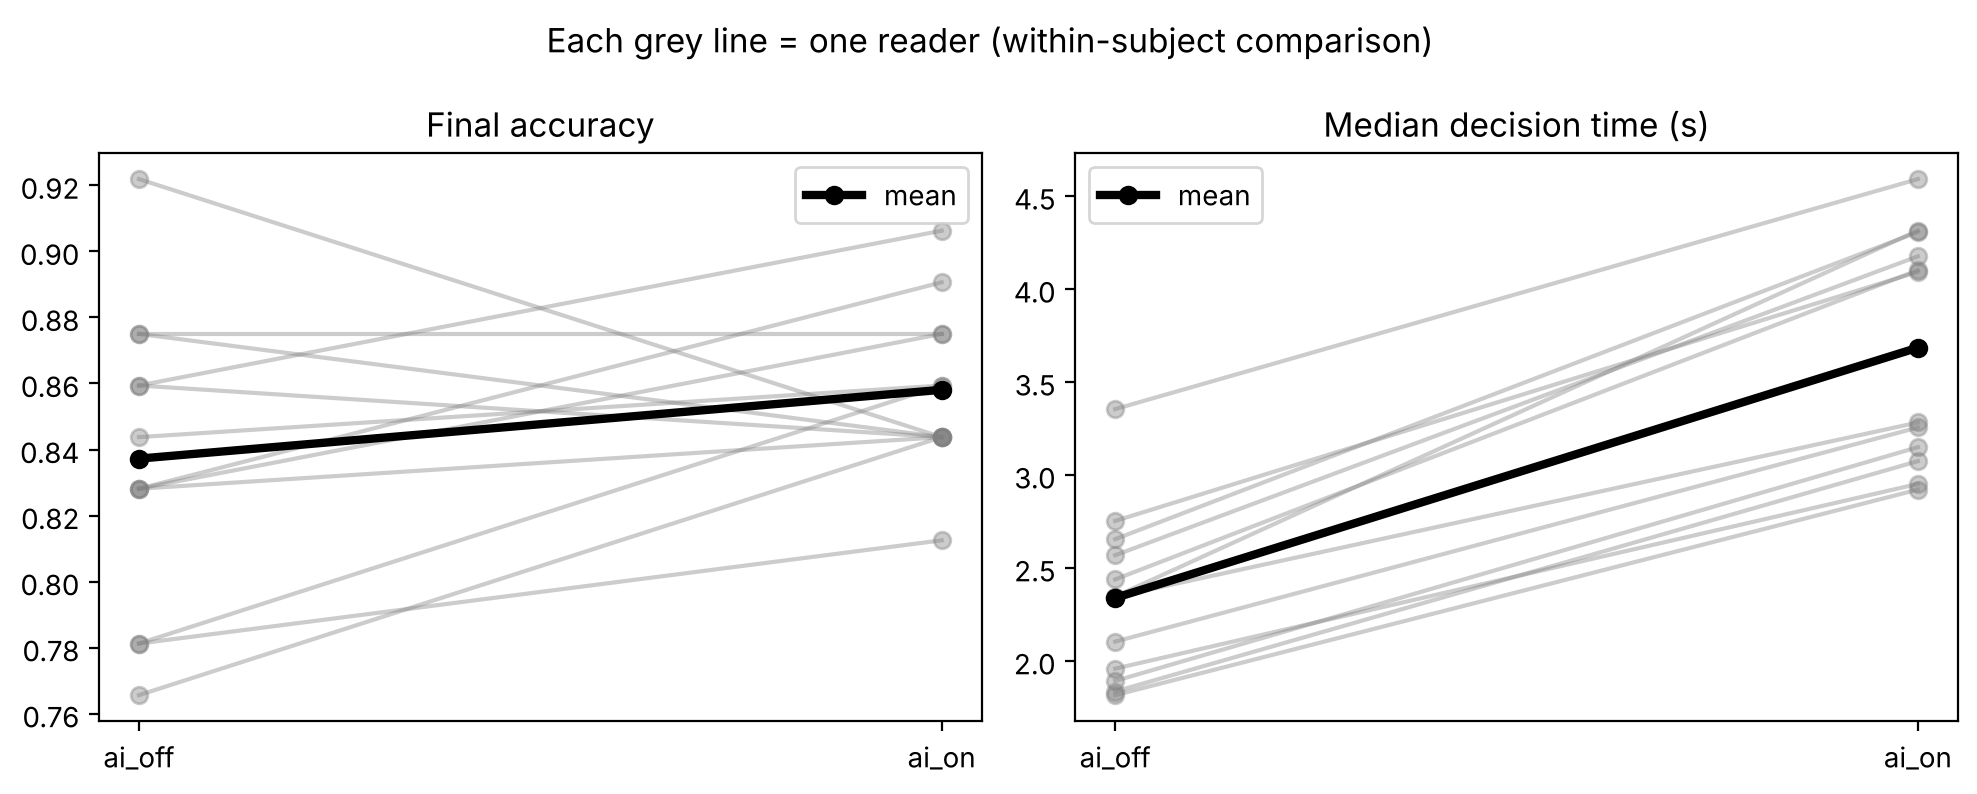

In [4]:
per_person = (d.groupby(["participant_id", "ai_condition"])
                .agg(accuracy=("correct_final", "mean"), median_time_s=("time_s", "median"))
                .reset_index())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
order = ["ai_off", "ai_on"]
for ax, col, title in [(axes[0], "accuracy", "Final accuracy"),
                       (axes[1], "median_time_s", "Median decision time (s)")]:
    wide = per_person.pivot(index="participant_id", columns="ai_condition", values=col)[order]
    for _, row in wide.iterrows():
        ax.plot(order, row.values, color="grey", alpha=0.4, marker="o")
    ax.plot(order, wide.mean().values, color="black", linewidth=3, marker="o", label="mean")
    ax.set_title(title)
    ax.legend()
plt.suptitle("Each grey line = one reader (within-subject comparison)")
plt.tight_layout()
plt.savefig(ROOT / "figures" / "accuracy_time_by_condition.png", dpi=150)
plt.show()

Every reader saw both conditions, so we use a **paired** test. With few readers we use
the non-parametric Wilcoxon signed-rank test.

In [5]:
from scipy.stats import wilcoxon

for col in ["accuracy", "median_time_s"]:
    wide = per_person.pivot(index="participant_id", columns="ai_condition", values=col)
    stat, p = wilcoxon(wide["ai_on"], wide["ai_off"])
    print(f"{col}: ai_off={wide['ai_off'].mean():.3f}, ai_on={wide['ai_on'].mean():.3f}, Wilcoxon p={p:.3f}")

accuracy: ai_off=0.837, ai_on=0.858, Wilcoxon p=0.162
median_time_s: ai_off=2.338, ai_on=3.684, Wilcoxon p=0.000


## 2. Before vs. after the advice (AI-on cases only)

Because we have each reader's decision **before** the AI, we can count exactly what the advice did:

- **helpful switch:** wrong before, right after
- **harmful switch:** right before, wrong after (this is automation bias in action)

In [6]:
on = d[d.ai_condition == "ai_on"].copy()
on["changed"] = on.initial != on.final
on["switch"] = np.select(
    [~on.changed, on.correct_final == 1, on.correct_final == 0],
    ["no change", "helpful switch", "harmful switch"], default="no change")

print(f"Accuracy before advice: {on.correct_initial.mean():.1%}")
print(f"Accuracy after advice:  {on.correct_final.mean():.1%}")
on.switch.value_counts()

Accuracy before advice: 81.0%
Accuracy after advice:  85.8%


switch
no change         635
helpful switch     85
harmful switch     48
Name: count, dtype: int64

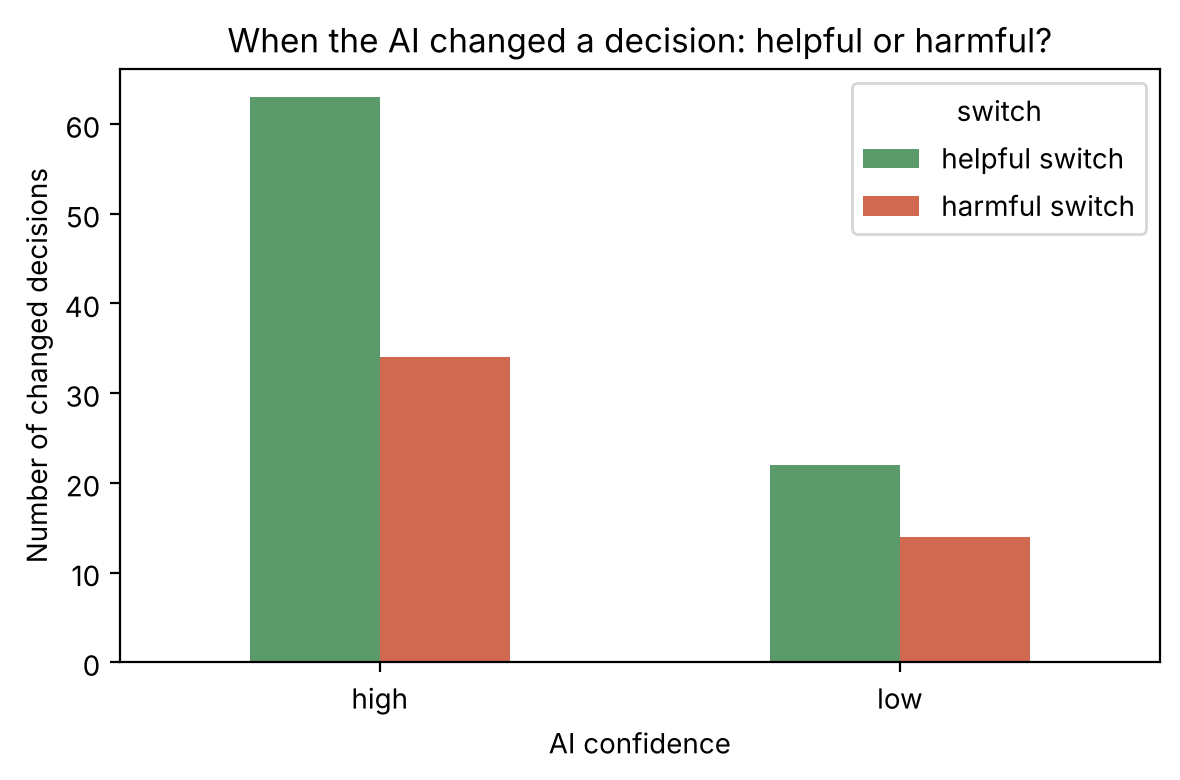

In [7]:
counts = on[on.changed].groupby(["ai_confidence", "switch"]).size().unstack(fill_value=0)
counts = counts.reindex(index=["high", "low"], columns=["helpful switch", "harmful switch"], fill_value=0)
ax = counts.plot(kind="bar", color=["#5b9b6b", "#d0694f"], figsize=(6, 4), rot=0)
ax.set_xlabel("AI confidence")
ax.set_ylabel("Number of changed decisions")
ax.set_title("When the AI changed a decision: helpful or harmful?")
plt.tight_layout()
plt.savefig(ROOT / "figures" / "switches.png", dpi=150)
plt.show()

## 3. Automation bias and calibrated trust

We look only at decisions where the reader's own first decision **disagreed** with the AI.
The question is: how often did they switch to the AI's answer?

- If they switch often when the AI is **wrong**, that is automation bias.
- If they switch less when the AI says its confidence is **low**, their trust is calibrated.

In [8]:
dis = on[on.initial != on.ai_flag].copy()
dis["ai_correct"] = np.where(dis.ai_flag == dis.ground_truth, "AI correct", "AI wrong")
dis["followed_ai"] = (dis.final == dis.ai_flag).astype(int)

table = (dis.groupby(["ai_confidence", "ai_correct"])
            .agg(n=("followed_ai", "size"), switch_rate=("followed_ai", "mean"))
            .round(2))
table

n  switch_rate
ai_confidence ai_correct                 
high          AI correct  80         0.79
              AI wrong    41         0.83
low           AI correct  48         0.46
              AI wrong    27         0.52

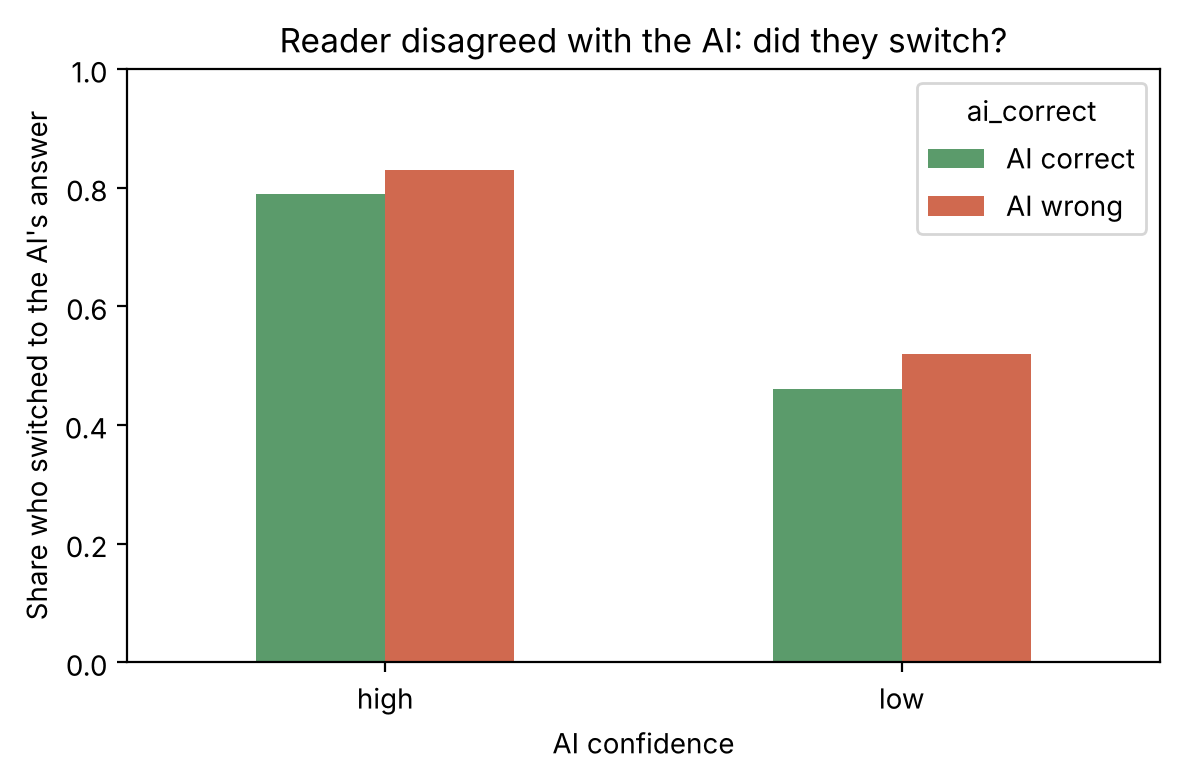

In [9]:
rates = table["switch_rate"].unstack().reindex(index=["high", "low"])
ax = rates.plot(kind="bar", color=["#5b9b6b", "#d0694f"], figsize=(6, 4), rot=0)
ax.set_ylim(0, 1)
ax.set_xlabel("AI confidence")
ax.set_ylabel("Share who switched to the AI's answer")
ax.set_title("Reader disagreed with the AI: did they switch?")
plt.tight_layout()
plt.savefig(ROOT / "figures" / "calibrated_trust.png", dpi=150)
plt.show()

## 4. A model closer to a real study

The same readers rate many regions, so decisions are **not independent**. A real study would
use models that account for this. Here, as a sketch:

- decision time (log scale) with a **random intercept per reader** (linear mixed model)
- accuracy with a logistic model clustered by reader (GEE)

A full analysis would also add the case as a random effect (multi-reader multi-case design).

In [10]:
import statsmodels.formula.api as smf
import statsmodels.api as sm

d["log_time"] = np.log(d.time_s)
m_time = smf.mixedlm("log_time ~ ai_condition", d, groups=d["participant_id"]).fit()
print(m_time.summary().tables[1])

m_acc = smf.gee("correct_final ~ ai_condition", groups="participant_id", data=d,
                family=sm.families.Binomial(), cov_struct=sm.cov_struct.Exchangeable()).fit()
print(m_acc.summary().tables[1])

                       Coef. Std.Err.       z  P>|z| [0.025 0.975]
Intercept              0.826    0.053  15.617  0.000  0.722  0.929
ai_condition[T.ai_on]  0.477    0.018  26.276  0.000  0.441  0.512
Group Var              0.032    0.039                             
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 1.6378      0.092     17.782      0.000       1.457       1.818
ai_condition[T.ai_on]     0.1615      0.097      1.664      0.096      -0.029       0.352


## 5. Limitations and next steps

- The data is simulated, and the behaviour model is deliberately simple.
- A real evaluation needs ethics approval at each site, informed consent from the readers,
  pseudonymised patient data, realistic cases and a sample-size calculation.
- Next steps: connect the logger to real ScanOMetrics output, run a small pilot with
  radiologists, and compare interface designs (advice first vs. decide first;
  showing uncertainty or not).